In [2]:
import pandas as pd 
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

In [6]:
df = load_iris()

In [8]:
X = df.data
y = df.target

In [40]:
y.shape

(150,)

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<Axes: >

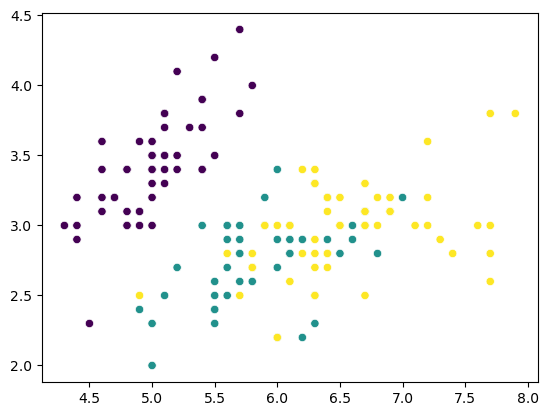

In [21]:
import seaborn as sns
sns.scatterplot(x = X[:,0],y=X[:,1],c=y)

In [25]:
from sklearn.cluster import KMeans 
model = KMeans(
    n_clusters = 3   
)
labels = model.fit_predict(X_scaled)

C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\User\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

<Axes: >

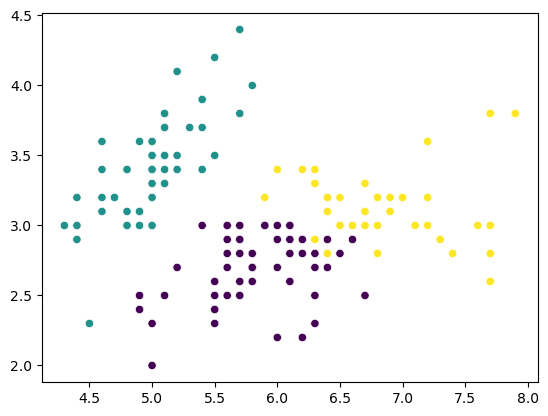

In [26]:
sns.scatterplot(x = X[:,0],y=X[:,1],c=labels)

# using Elbow & Silhouette

C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows wi

<Axes: >

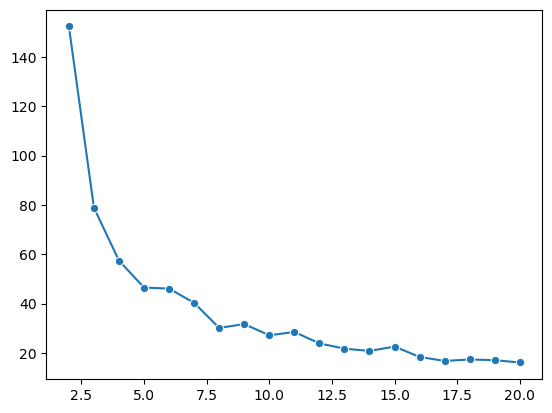

In [41]:
wcss =[]
for k in range(2,21):
    model = KMeans(n_clusters = k)
    labels = model.fit_predict(X)
    wcss.append(model.inertia_)
sns.lineplot( x=range(2,21) , y = wcss , marker= 'o')

In [35]:
!pip install kneed

In [43]:
from kneed import KneeLocator
knee = KneeLocator(range(2,21),wcss,curve='convex',direction='decreasing')
print(f"Knee = {knee.elbow}")

Knee = 5


C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\User\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows wi

<Axes: >

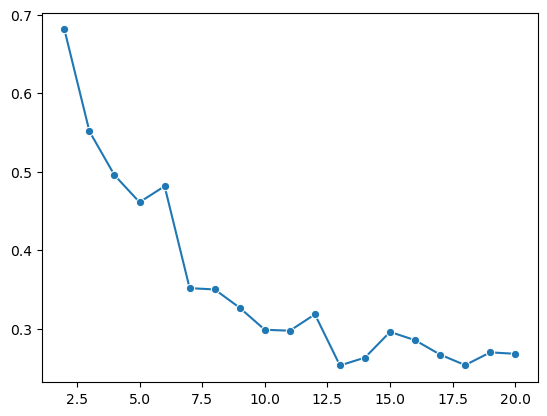

In [47]:
from sklearn.metrics import silhouette_score
scores = []
for k in range(2,21):
    model = KMeans(n_clusters = k)
    labels = model.fit_predict(X)
    sil = silhouette_score(X,labels)
    scores.append(sil)
sns.lineplot( x=range(2,21) , y = scores , marker= 'o')